# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os
from torch import optim

In [ ]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

train (11959, 28, 28, 3) uint8 min/max: 0 255 | y: (11959,)
val (1712, 28, 28, 3) uint8 min/max: 0 255 | y: (1712,)
test (3421, 28, 28, 3) uint8 min/max: 0 255 | y: (3421,)
Kanały: 3
NaN: False
duplikaty w train: 8


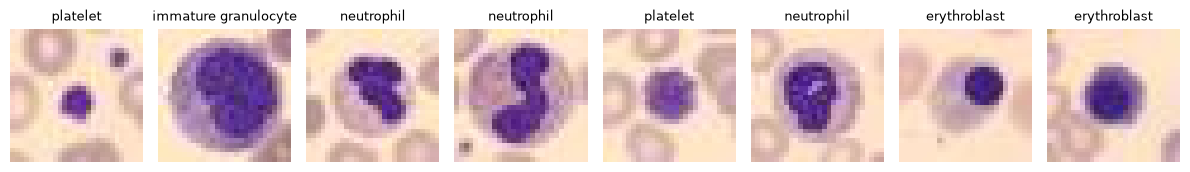

                      train  val  test
basophil                852  122   244
eosinophil             2181  312   624
erythroblast           1085  155   311
immature granulocyte   2026  290   579
lymphocyte              849  122   243
monocyte                993  143   284
neutrophil             2330  333   666
platelet               1643  235   470


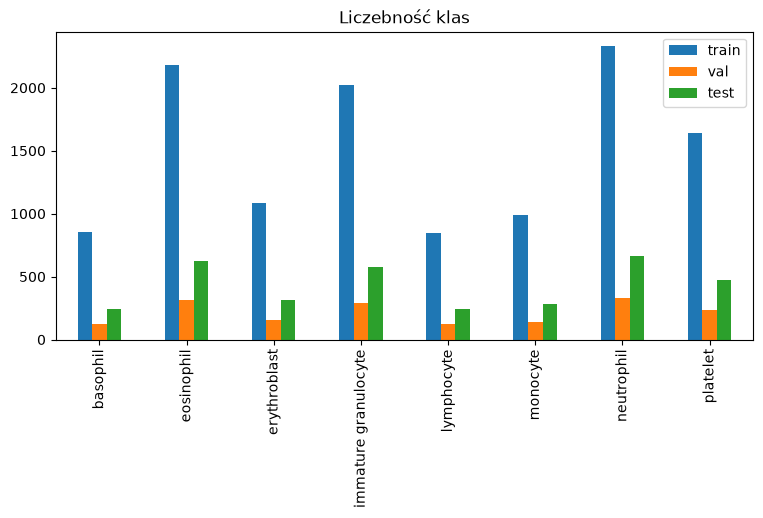

In [29]:
X_train, y_train = data["train_images"], data["train_labels"].ravel()
X_val,   y_val   = data["val_images"],   data["val_labels"].ravel()
X_test,  y_test  = data["test_images"],  data["test_labels"].ravel()
for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(name, X.shape, X.dtype, "min/max:", X.min(), X.max(), "| y:", y.shape)
print("Kanały:", X_train.shape[-1])
print("NaN:", np.isnan(X_train.astype(float)).any())
n_dup = len(X_train) - len(np.unique(X_train.reshape(len(X_train), -1), axis=0))
print("duplikaty w train:", n_dup)

class_names = ["basophil", "eosinophil", "erythroblast", "immature granulocyte",
               "lymphocyte", "monocyte", "neutrophil", "platelet"]

counts = pd.DataFrame({
    "train": np.bincount(y_train, minlength=8),
    "val":   np.bincount(y_val,   minlength=8),
    "test":  np.bincount(y_test,  minlength=8),
}, index=class_names)
n_samples = 8

plt.figure(figsize=(12, 3))
for i in range(n_samples):
    plt.subplot(1, n_samples, i + 1)
    plt.imshow(X_train[i])
    label_idx = y_train[i]
    plt.title(class_names[label_idx], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()
print(counts)
counts.plot.bar(figsize=(9, 4)); plt.title("Liczebność klas"); plt.show()
import torch
from torch.utils.data import TensorDataset, DataLoader

def to_dataloader(X_np, y_np, batch_size=64, shuffle=False):
    # 1. Konwersja pikseli z (N, 28, 28, 3) do (N, 3, 28, 28) i przeskalowanie do [0, 1]
    X_tensor = torch.from_numpy(X_np).permute(0, 3, 1, 2).float() / 255.0
    y_tensor = torch.from_numpy(y_np).long()
    dataset = TensorDataset(X_tensor, y_tensor)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

BATCH_SIZE = 128

dataloader_treningowy = to_dataloader(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
dataloader_walidacyjny = to_dataloader(X_val, y_val, batch_size=BATCH_SIZE, shuffle=False)
dataloader_testowy     = to_dataloader(X_test, y_test, batch_size=BATCH_SIZE, shuffle=False)

używamy pętli do analizy naszych danych treningowych, walidacyjnych i testowych. widzimy ze zbior terningowy jest najwiekszy. kazdy zbiorze ma obrazy 28x28 RGB,używamy reshape od len(x_train) aby zostawic ilosc orazow i -1 aby reszte informacji połączyc w wiersze wiec zostaje nam (11959,2352) kazde wiersz ma 2352 ciagu znaków używamy uniqe aby zoabzcyc ile obrazkow jest takich samych, Dokonujemy wstępnej analizy obrazków na podstawie próbek jak możemy zobaczyć nie widać żadnych niepokojacych elementów. następnie lcizymy iosc krwinek w kazdym zbiorze zeby sprawdzic rozklad danych mozemy zauwazyc ze jest on nierównomierny dlatego użyjemy f1.

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [ ]:
class MojaSiec(nn.Module):
    def __init__(self):
       
        super(MojaSiec, self).__init__() 
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32,kernel_size=3,padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.akt1 = nn.PReLU(32)
        self.cut1 = nn.MaxPool2d(2,2) #14 x 14

        self.conv2 = nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.akt2 = nn.PReLU(64)
        self.cut2 = nn.MaxPool2d(2,2) 

        #7x7
        self.splaszcz = nn.Flatten()
        self.linear = nn.Linear(in_features=64*7*7,out_features=128)
        self.bn1d = nn.BatchNorm1d(128)
        self.aktlin = nn.PReLU(128)
        self.wyjscie = nn.Linear(in_features=128,out_features=8)
    def forward(self, x):
     
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.akt1(x)
        x = self.cut1(x)
        
       
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.akt2(x)
        x = self.cut2(x)

        x = self.splaszcz(x)
        x = self.linear(x)
        x = self.bn1d(x)
        x = self.aktlin(x)
        x = self.wyjscie(x)
        return x

model = MojaSiec()
kryterium = nn.CrossEntropyLoss() #funkcja wypsiujac blad
optymalizator = optim.Adam(model.parameters(), lr=0.001)
najlepszy_f1, najlepsze_wagi = 0, None
hist = {"Epoka":[],"train_loss": [], "val_loss": [], "val_f1": []}
for epoka in range(10):
    suma =0 
    hist["Epoka"].append(epoka+1)
    model.train()
    for xb,yb in dataloader_treningowy:
        optymalizator.zero_grad()
        strata = kryterium(model(xb),yb)
        strata.backward()
        optymalizator.step()
        suma += strata.item() *len(xb)
    hist["train_loss"].append(suma/len(dataloader_treningowy.dataset))

    model.eval()
    model.load_state_dict(najlepsze_wagi)
    suma = 0 
    pred =[]
    true =[]
    with torch.no_grad():
        for xb,yb in dataloader_walidacyjny:
            odp = model(xb)
            suma += kryterium(odp,yb).item() * len(xb)
            pred.append(odp.argmax(1))
            true.append(yb)
    f1 = f1_score(torch.cat(true), torch.cat(pred), average="macro")
    hist["val_loss"].append(suma / len(dataloader_walidacyjny.dataset))
    hist["val_f1"].append(f1)
    print(f"epoka {epoka+1}: train_loss={hist['train_loss'][-1]} "
          f"val_loss={hist['val_loss'][-1]} val_macroF1={f1}")
    if f1 > najlepszy_f1:
        najlepszy_f1 = f1
        najlepsze_wagi = {k: v.clone() for k, v in model.state_dict().items()}

epoka 1: train_loss=0.4875 val_loss=0.4067 val_macroF1=0.8218
epoka 2: train_loss=0.2559 val_loss=0.4181 val_macroF1=0.8263
epoka 3: train_loss=0.1946 val_loss=0.3735 val_macroF1=0.8521
epoka 4: train_loss=0.1499 val_loss=0.4801 val_macroF1=0.8200
epoka 5: train_loss=0.1235 val_loss=0.3392 val_macroF1=0.8707
epoka 6: train_loss=0.0938 val_loss=0.3383 val_macroF1=0.8473
epoka 7: train_loss=0.0789 val_loss=0.2579 val_macroF1=0.9037
epoka 8: train_loss=0.0576 val_loss=0.2302 val_macroF1=0.9185
epoka 9: train_loss=0.0464 val_loss=0.4162 val_macroF1=0.8717
epoka 10: train_loss=0.0356 val_loss=0.4272 val_macroF1=0.8545


Obraz wejściowy ma rozmiar 28×28 i 3 kanały (R, G, B). Warstwa Conv2d przesuwa po obrazie filtr (kernel_size=3, czyli okno 3×3) i w każdym miejscu liczy sumę ważoną pikseli ze wszystkich kanałów. Wagi filtrów nie są z góry zadane, tylko uczone w treningu na podstawie funkcji kosztu. Każdy filtr uczy się wykrywać inny wzorzec, np. krawędź, plamę czy teksturę. Parametr padding=1 dodaje ramkę zer wokół obrazu, dzięki czemu po konwolucji rozmiar pozostaje 28×28.

Pierwsza warstwa zamienia 3 kanały wejściowe na 32 mapy cech (wyniki 32 różnych filtrów), a druga zwiększa je do 64. Liczby kanałów to potęgi dwójki, zgodnie z przyjętą konwencją. Po każdej konwolucji stosujemy MaxPool2d(2,2), który z każdego okna 2×2 bierze największą wartość i zmniejsza obraz o połowę: 28×28 → 14×14 → 7×7. Zmniejsza to liczbę obliczeń i daje odporność na małe przesunięcia obiektu.

Po dwóch blokach mapy cech są spłaszczane do wektora o długości 64·7·7 = 3136. Warstwa Linear redukuje go do 128 wartości, a warstwa wyjściowa do 8 wartości (logitów), po jednej dla każdej klasy komórek krwi.

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

Wczytano najlepszy model z val_macroF1 = 0.9185279555724262
Ostateczny test_macroF1: 0.9090
--- Szczegółowy raport dla każdej klasy ---
                      precision    recall  f1-score   support

            basophil     0.8770    0.9057    0.8911       244
          eosinophil     0.9608    0.9824    0.9715       624
        erythroblast     0.9389    0.9389    0.9389       311
immature granulocyte     0.8068    0.8653    0.8350       579
          lymphocyte     0.8538    0.9136    0.8827       243
            monocyte     0.9259    0.7042    0.8000       284
          neutrophil     0.9648    0.9459    0.9553       666
            platelet     0.9979    0.9979    0.9979       470

            accuracy                         0.9202      3421
           macro avg     0.9157    0.9067    0.9090      3421
        weighted avg     0.9221    0.9202    0.9196      3421



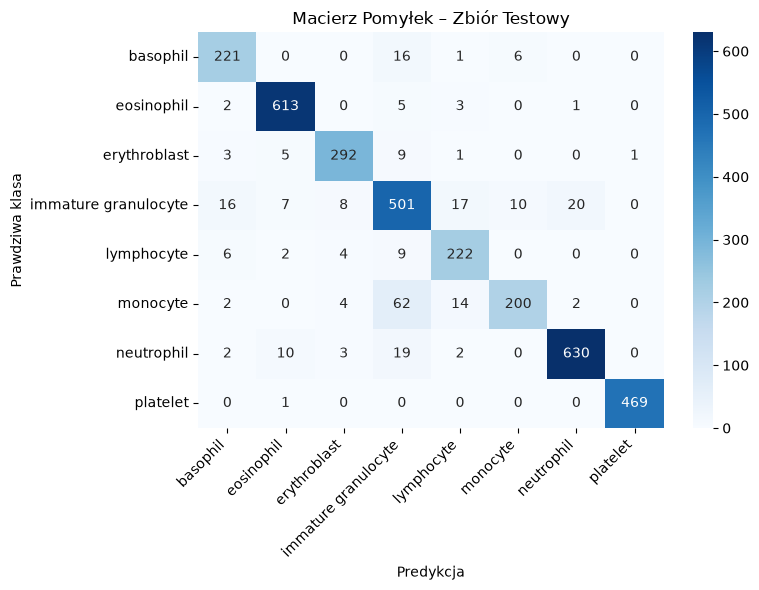

In [34]:
if najlepsze_wagi is not None:
    model.load_state_dict(najlepsze_wagi)
    print(f"Wczytano najlepszy model z val_macroF1 = {najlepszy_f1}")
model.eval()
pred_test = []
true_test = []
with torch.no_grad():
    for xb, yb in dataloader_testowy:
        odp = model(xb)
        pred_test.append(odp.argmax(1))
        true_test.append(yb)

f1_test = f1_score(torch.cat(true_test), torch.cat(pred_test), average="macro")
print(f"Ostateczny test_macroF1: {f1_test:.4f}")
print("--- Szczegółowy raport dla każdej klasy ---")
print(classification_report(torch.cat(true_test), torch.cat(pred_test), target_names=class_names, digits=4))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(torch.cat(true_test), torch.cat(pred_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=class_names, yticklabels=class_names)
plt.title("Macierz Pomyłek – Zbiór Testowy")
plt.xlabel("Predykcja")
plt.ylabel("Prawdziwa klasa")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 1. Ocena modelu na zbiorze testowym i analiza pomyłek

* **Przebieg ewaluacji:** 
  Po zakończeniu procesu uczenia przywracamy najlepszy zapamiętany stan modelu (`model.load_state_dict(najlepsze_wagi)`), wyłączamy wyliczanie gradientów (`eval()` + `torch.no_grad()`) i przeprowadzamy predykcję na oficjalnym zbiorze testowym (`dataloader_testowy`). Wyniki z poszczególnych batchy łączy się w pojedyncze wektory przy użyciu `torch.cat()`.
* **Dobór metryk:** 
  Do ostatecznej oceny stosujemy **Macro F1-Score** (oraz Precision/Recall). Ze względu na nierównowagę klas w zbiorze danych, metryka uśredniana w trybie *macro* pozwala traktować każdą z 8 klas komórek jednakowo, unikając faworyzowania klas dominujących.
* **Analiza pomyłek:** 
  Wizualizujemy macierz pomyłek (*Confusion Matrix*) w formie mapy ciepła, aby zweryfikować, które klasy komórek sieć ze sobą najczęściej myli (np. wychwytując różnice budowy jądra między dojrzałymi a niedojrzałymi granulocytami).

---

### 2. Wizualne wyjaśnianie decyzji modelu – Grad-CAM

* **Zasada działania:** 
  Do analizy interpretowalności decyzji sieci wykorzystujemy metodę **Grad-CAM** (*Gradient-weighted Class Activation Mapping*). Oblicza ona gradienty z ostatniej warstwy konwolucyjnej (`conv2`) względem wybranej klasy wyjściowej i generuje mapę aktywacji. Po nałożeniu na oryginalny obraz pokazuje ona (kolorem czerwonym/żółtym), które obszary miały decydujący wpływ na wynik.
* **Analiza wyników:** 
  Generujemy mapę aktywacji dla predykcji:
  * **Poprawnych:** Sprawdzamy, czy sieć podejmuje decyzje na podstawie biologicznie istotnych struktur (jądro, cytoplazma).
  * **Błędnych:** Identyfikujemy przyczynę pomyłki (np. skupienie uwagi na tle, krawędzi obrazu lub sąsiednich artefaktach).

---

### 3. Ograniczenia metody Grad-CAM

1. **Niska rozdzielczość przestrzenna:** Mapy aktywacji wyznaczane są na podstawie głębokiej warstwy konwolucyjnej o małym wymiarze (np. $7 \times 7$). Po rozciągnięciu do rozmiaru wejściowego ($28 \times 28$) obraz jest rozmyty i wskazuje ogólną plamę aktywacji zamiast precyzyjnych konturów.
2. **Brak szczegółów mikroskopowych:** Grad-CAM lokuje ogólny obszar zainteresowania, ale nie obrazuje drobnych cech faktury (np. ułożenia chromatyny wewnątrz jądra).
3. **Uwzględnianie tylko cech pozytywnych:** Ze względu na zastosowanie aktywacji ReLU na gradientach, metoda wizualizuje wyłącznie cechy, które *potwierdzają* wybraną klasę, ignorując te, które świadczyły przeciwko niej.

---

### 4. Źródło

> **Grad-CAM:** Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization*. In Proceedings of the IEEE International Conference on Computer Vision (ICCV), pp. 618-626.

## Oddanie zadania

#### Źródła i narzędzia
1.Dokumentacja PyTorch (torch.nn.CrossEntropyLoss, torch.optim.Adam, torch.nn.PReLU, torch.nn.BatchNorm2d), pytorch.org/docs.

2.Narzędzie AI: Claude Sonnet 5.5 (Anthropic, claude.ai), użyte do wyjaśniania pojęć, pomocy przy kodzie i redakcji opisów. Kod uruchomiłem, zweryfikowałem i zinterpretowałem samodzielnie.